In [1]:
%pip -q install ucimlrepo shap joblib

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import shap

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
    PrecisionRecallDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# Load the UCI Heart Disease dataset
heart_disease = fetch_ucirepo(id=45)

X = heart_disease.data.features.copy()
y = heart_disease.data.targets.copy()

df = X.copy()
df["target"] = y.iloc[:, 0]

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values per column:")
display(df.isnull().sum())

print("\nOriginal target distribution:")
display(df["target"].value_counts().sort_index())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe().T)

Column names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB

Missing values per column:


,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0



Original target distribution:


,count
target,
0,164
1,55
2,36
3,35
4,13



Duplicate rows: 0

Statistical summary:


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


In [4]:
# Convert invalid missing-value markers to NaN, if present
df = df.replace(["?", "NA", "N/A", ""], np.nan)

# Convert columns to numeric values
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows with a missing target
df = df.dropna(subset=["target"]).copy()

# Convert original target into binary classification:
# 0 = no disease
# 1, 2, 3, 4 = disease present
df["target"] = (df["target"] > 0).astype(int)

# Remove duplicate records
df = df.drop_duplicates().reset_index(drop=True)

# Separate features and target
X = df.drop(columns=["target"])
y = df["target"]

print("Cleaned dataset shape:", df.shape)
print("\nTarget distribution:")
print(y.value_counts().rename(index={0: "No disease", 1: "Disease present"}))

print("\nMissing values after cleaning:")
display(X.isnull().sum())

print("\nTarget conversion completed.")

Cleaned dataset shape: (303, 14)

Target distribution:
target
No disease         164
Disease present    139
Name: count, dtype: int64

Missing values after cleaning:


,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0



Target conversion completed.


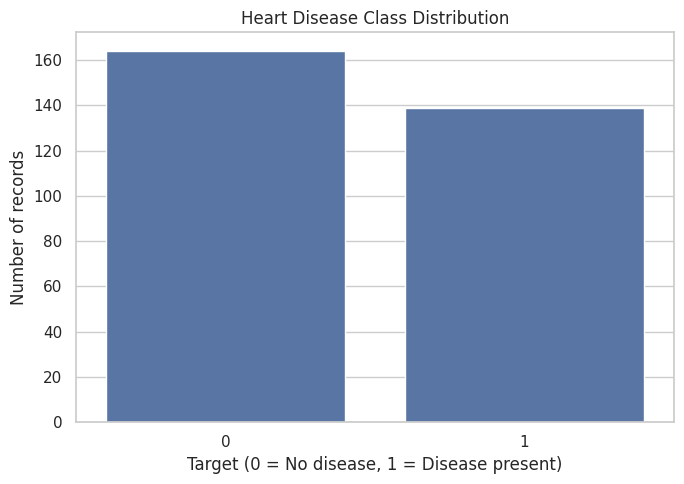

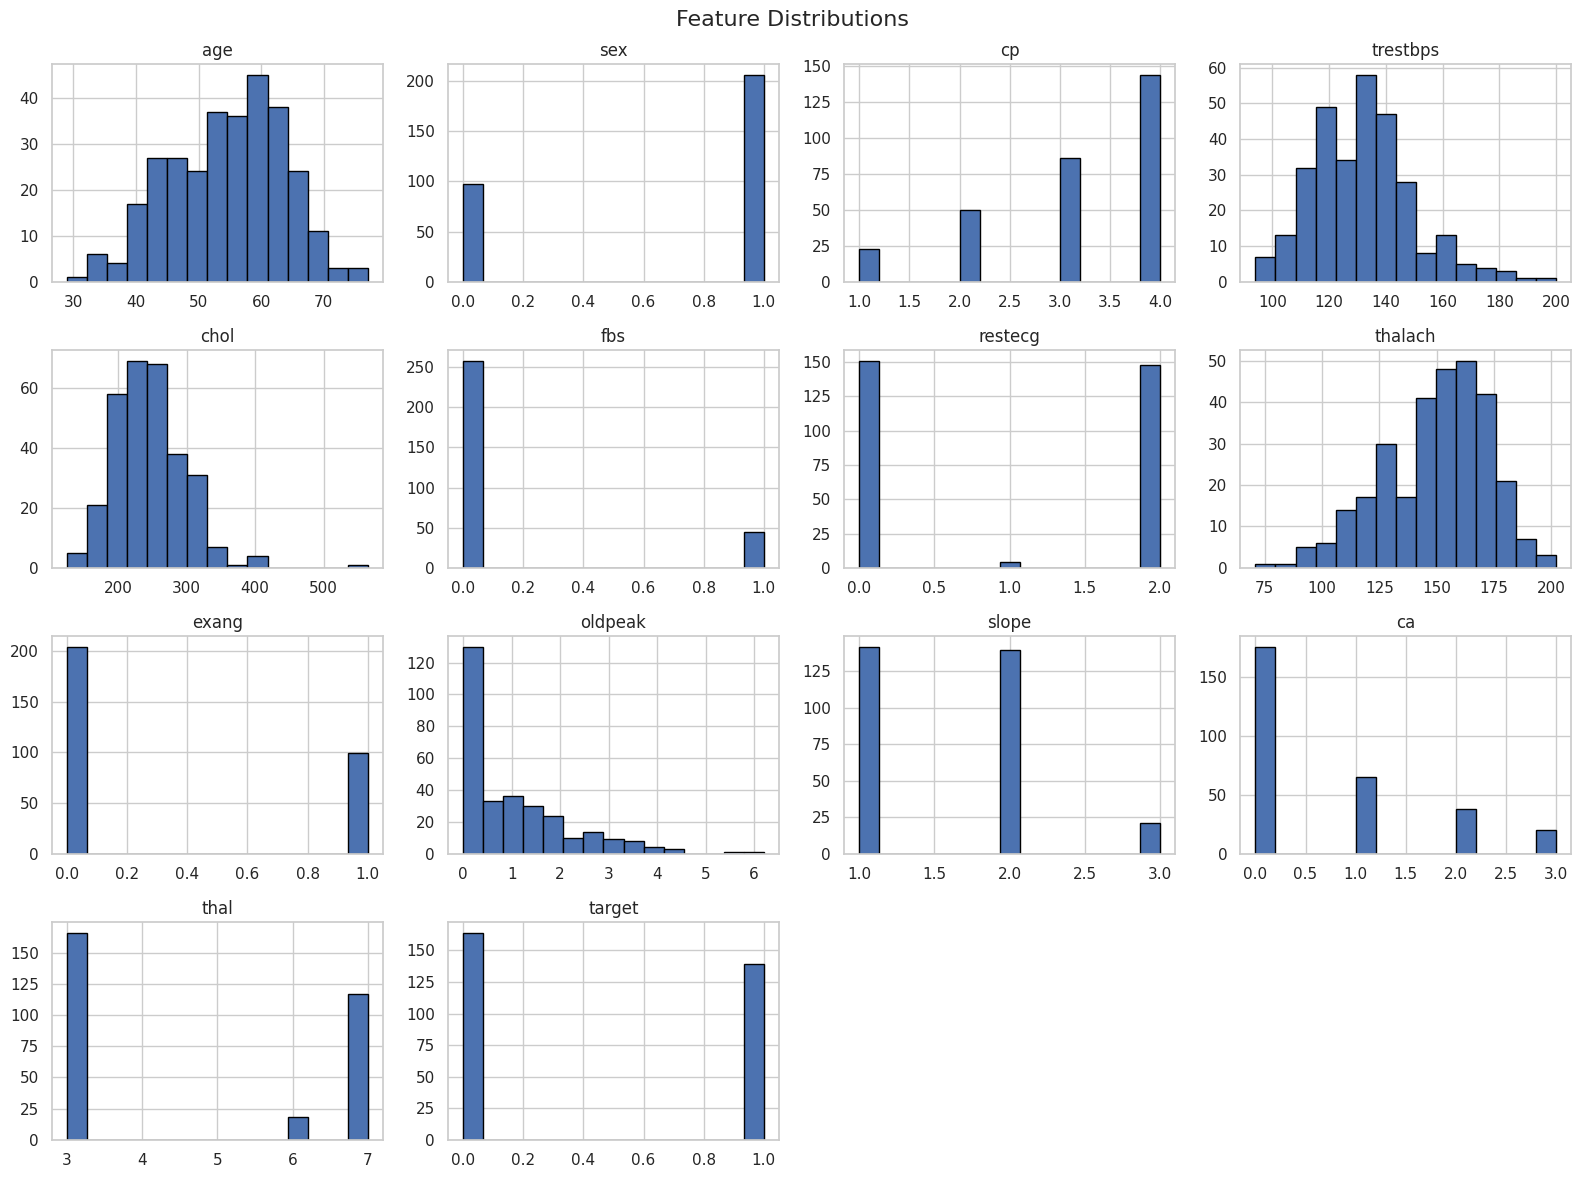

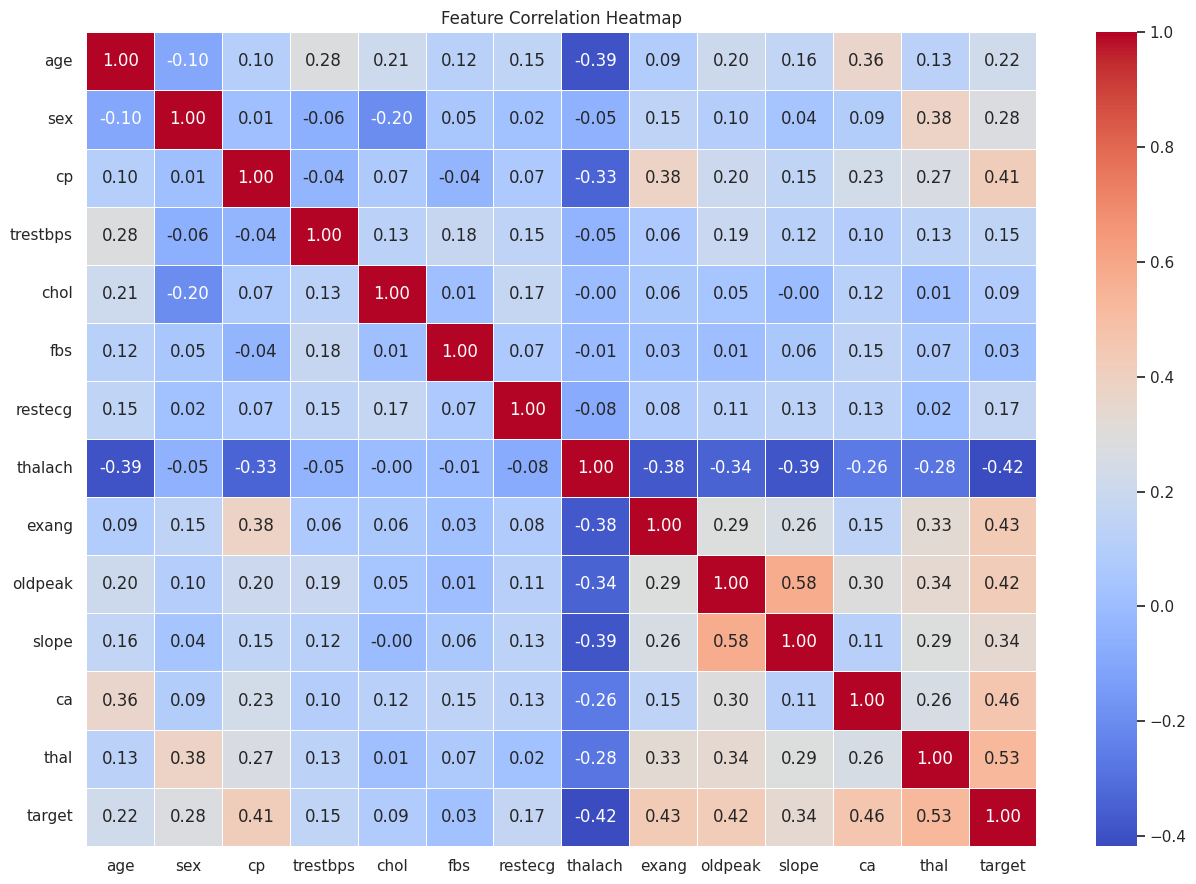

In [5]:
# Target distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="target")
plt.title("Heart Disease Class Distribution")
plt.xlabel("Target (0 = No disease, 1 = Disease present)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

# Feature distributions
df.hist(figsize=(16, 12), bins=15, edgecolor="black")
plt.suptitle("Feature Distributions", fontsize=16)
plt.tight_layout()
plt.show()

# Correlation heatmap
plt.figure(figsize=(13, 9))
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

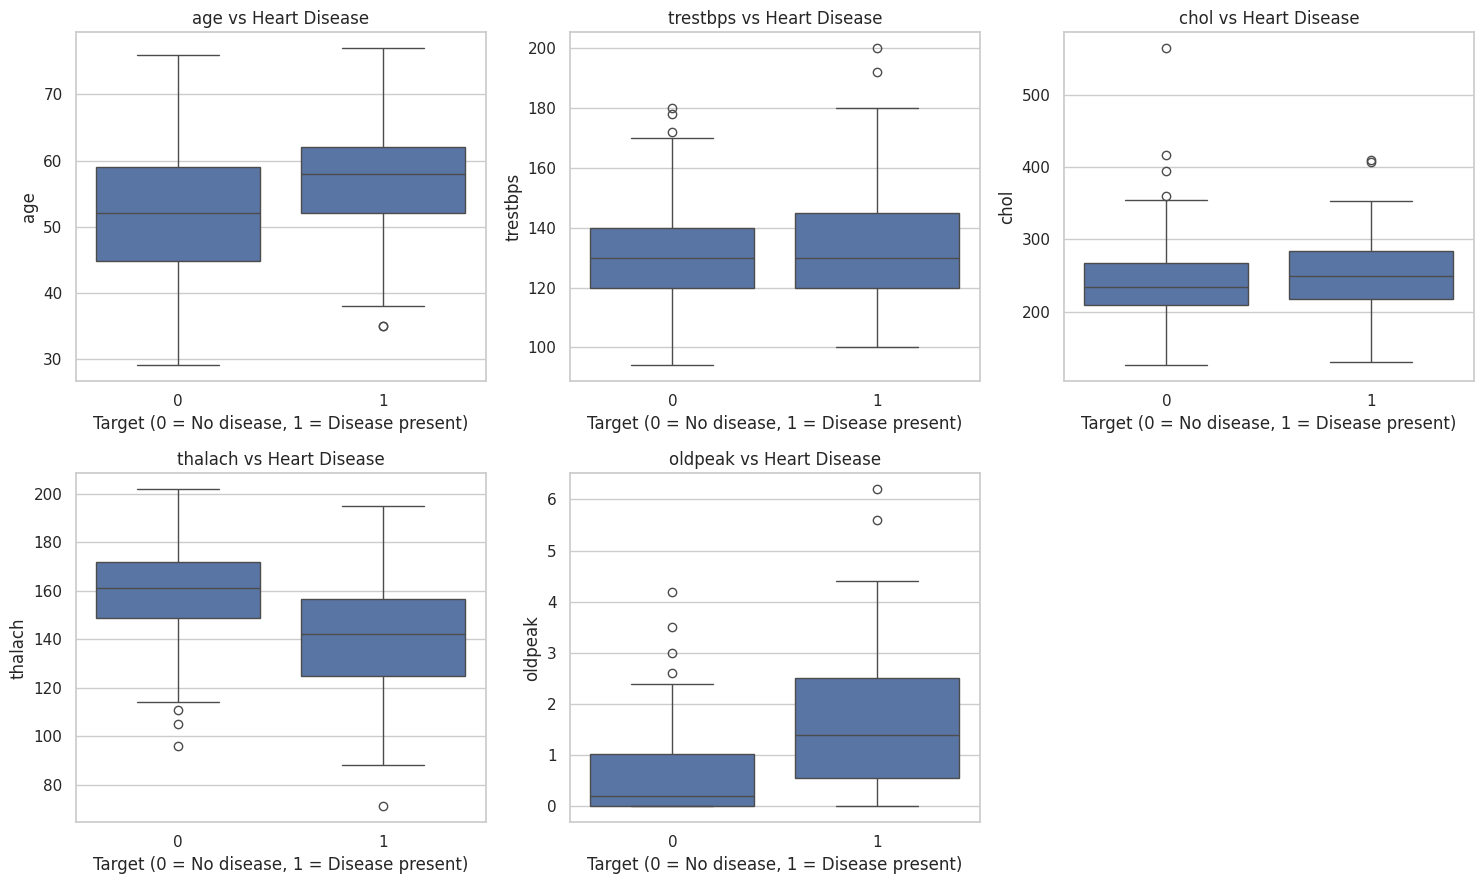

In [6]:
features_to_plot = [
    "age", "trestbps", "chol",
    "thalach", "oldpeak"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, feature in enumerate(features_to_plot):
    sns.boxplot(
        data=df,
        x="target",
        y=feature,
        ax=axes[i]
    )
    axes[i].set_title(f"{feature} vs Heart Disease")
    axes[i].set_xlabel("Target (0 = No disease, 1 = Disease present)")

axes[-1].axis("off")

plt.tight_layout()
plt.show()

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training feature shape: (242, 13)
Testing feature shape: (61, 13)

Training target distribution:
target
0    0.541
1    0.459
Name: proportion, dtype: float64

Testing target distribution:
target
0    0.541
1    0.459
Name: proportion, dtype: float64


In [8]:
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ]),

    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVC(
            kernel="rbf",
            probability=True,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", GradientBoostingClassifier(
            n_estimators=100,
            learning_rate=0.05,
            max_depth=2,
            random_state=RANDOM_STATE
        ))
    ])
}

print("Models prepared:")
for name in models:
    print("-", name)

Models prepared:
- Logistic Regression
- SVM
- Random Forest
- Gradient Boosting


In [9]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1 Score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)
cv_results_df = cv_results_df.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

display(
    cv_results_df.style.format({
        "Accuracy": "{:.3f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1 Score": "{:.3f}",
        "ROC-AUC": "{:.3f}"
    })
)

best_model_name = cv_results_df.iloc[0]["Model"]
print("Best model by mean cross-validation ROC-AUC:", best_model_name)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.814,0.815,0.774,0.791,0.896
1,Random Forest,0.802,0.805,0.756,0.776,0.883
2,SVM,0.826,0.841,0.774,0.800,0.882
3,Gradient Boosting,0.797,0.792,0.766,0.775,0.870


Best model by mean cross-validation ROC-AUC: Logistic Regression


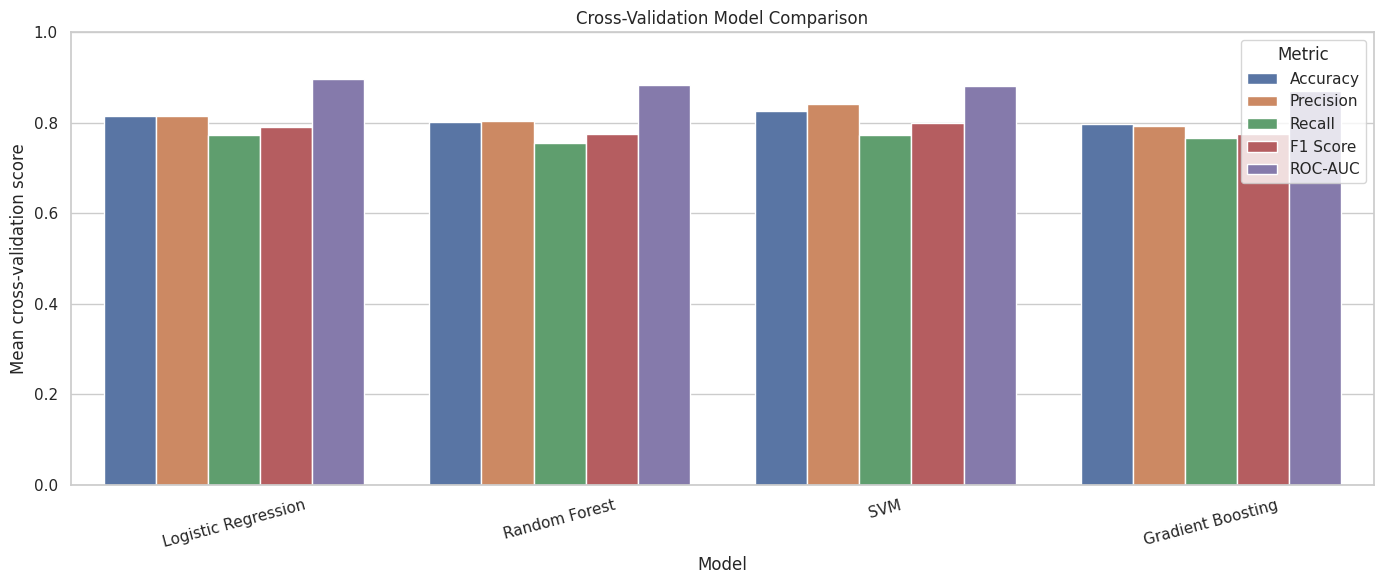

In [10]:
metrics_to_plot = [
    "Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"
]

cv_results_long = cv_results_df.melt(
    id_vars="Model",
    value_vars=metrics_to_plot,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(14, 6))
sns.barplot(
    data=cv_results_long,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Cross-Validation Model Comparison")
plt.ylabel("Mean cross-validation score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [11]:
best_model = models[best_model_name]

# Fit only on the training set
best_model.fit(X_train, y_train)

# Predictions on the untouched test set
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

test_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}

print("Selected model:", best_model_name)
print("\nTest-set metrics:")

for metric, score in test_metrics.items():
    print(f"{metric}: {score:.3f}")

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No disease", "Disease present"],
    zero_division=0
))

Selected model: Logistic Regression

Test-set metrics:
Accuracy: 0.869
Precision: 0.812
Recall: 0.929
F1 Score: 0.867
ROC-AUC: 0.950

Classification report:
                 precision    recall  f1-score   support

     No disease       0.93      0.82      0.87        33
Disease present       0.81      0.93      0.87        28

       accuracy                           0.87        61
      macro avg       0.87      0.87      0.87        61
   weighted avg       0.88      0.87      0.87        61



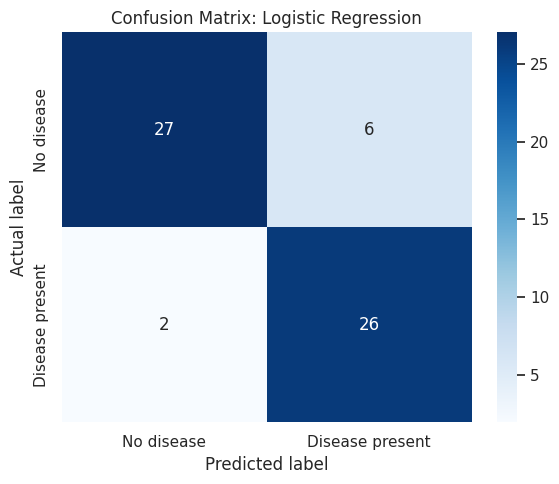

In [12]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No disease", "Disease present"],
    yticklabels=["No disease", "Disease present"]
)

plt.title(f"Confusion Matrix: {best_model_name}")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.tight_layout()
plt.show()

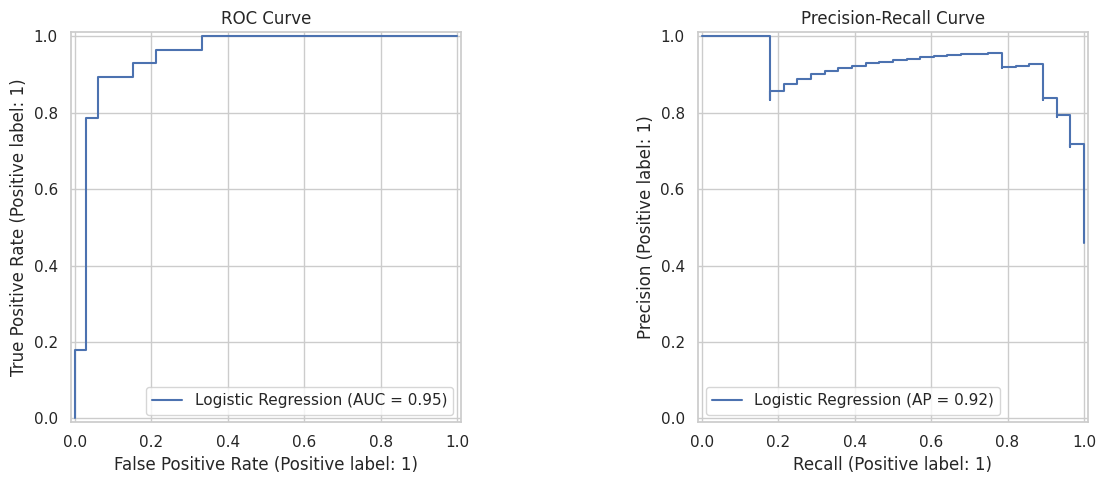

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    ax=axes[0],
    name=best_model_name
)
axes[0].set_title("ROC Curve")

PrecisionRecallDisplay.from_predictions(
    y_test,
    y_prob,
    ax=axes[1],
    name=best_model_name
)
axes[1].set_title("Precision-Recall Curve")

plt.tight_layout()
plt.show()

,Feature,Importance
11,ca,1.117116
12,thal,0.672825
1,sex,0.669374
2,cp,0.534356
8,exang,0.385257
10,slope,0.361985
7,thalach,0.359250
3,trestbps,0.313150
4,chol,0.226305
5,fbs,0.225438


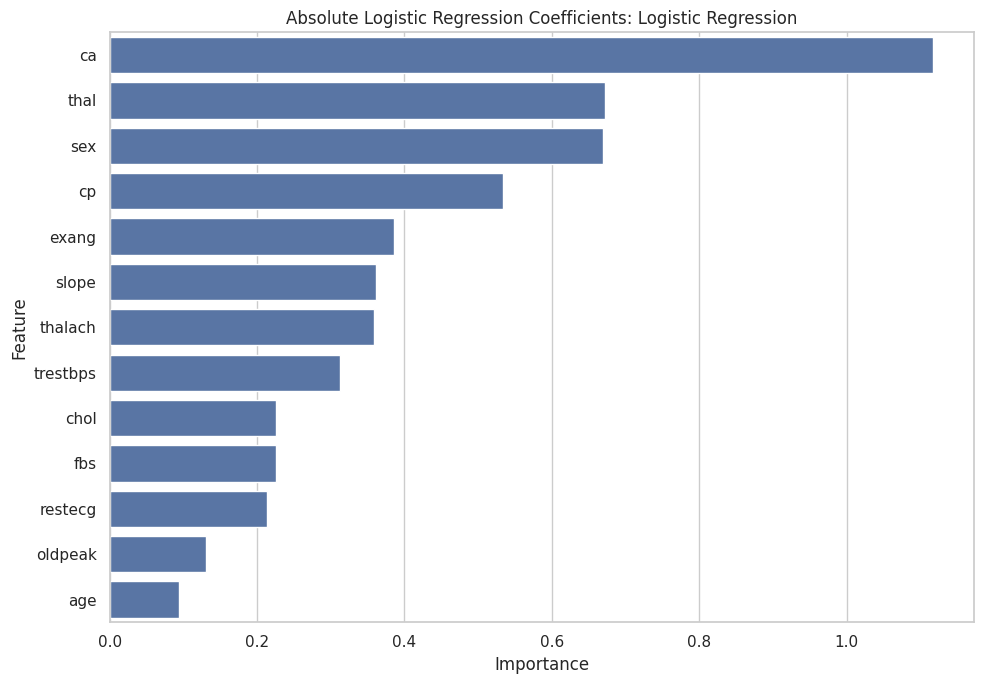

In [14]:
fitted_estimator = best_model.named_steps["model"]

if hasattr(fitted_estimator, "feature_importances_"):
    importance_values = fitted_estimator.feature_importances_
    importance_title = "Tree-Based Feature Importance"

elif hasattr(fitted_estimator, "coef_"):
    importance_values = np.abs(fitted_estimator.coef_[0])
    importance_title = "Absolute Logistic Regression Coefficients"

else:
    importance_values = None
    print(
        "This model does not provide native feature importance. "
        "Use the SHAP section below."
    )

if importance_values is not None:
    importance_df = pd.DataFrame({
        "Feature": X_train.columns,
        "Importance": importance_values
    }).sort_values("Importance", ascending=False)

    display(importance_df)

    plt.figure(figsize=(10, 7))
    sns.barplot(
        data=importance_df,
        x="Importance",
        y="Feature"
    )
    plt.title(f"{importance_title}: {best_model_name}")
    plt.tight_layout()
    plt.show()

In [15]:
# Use a small background sample and a small test sample
background = X_train.sample(
    n=min(40, len(X_train)),
    random_state=RANDOM_STATE
)

explain_data = X_test.sample(
    n=min(30, len(X_test)),
    random_state=RANDOM_STATE
)

# Explain the probability of class 1 (disease present)
def predict_disease_probability(data):
    if isinstance(data, pd.DataFrame):
        input_df = data.copy()
    else:
        input_df = pd.DataFrame(data, columns=X_train.columns)

    return best_model.predict_proba(input_df)[:, 1]

explainer = shap.PermutationExplainer(
    predict_disease_probability,
    background
)

shap_values = explainer(
    explain_data,
    max_evals=2 * X_train.shape[1] + 1
)

print("SHAP values calculated.")

SHAP values calculated.


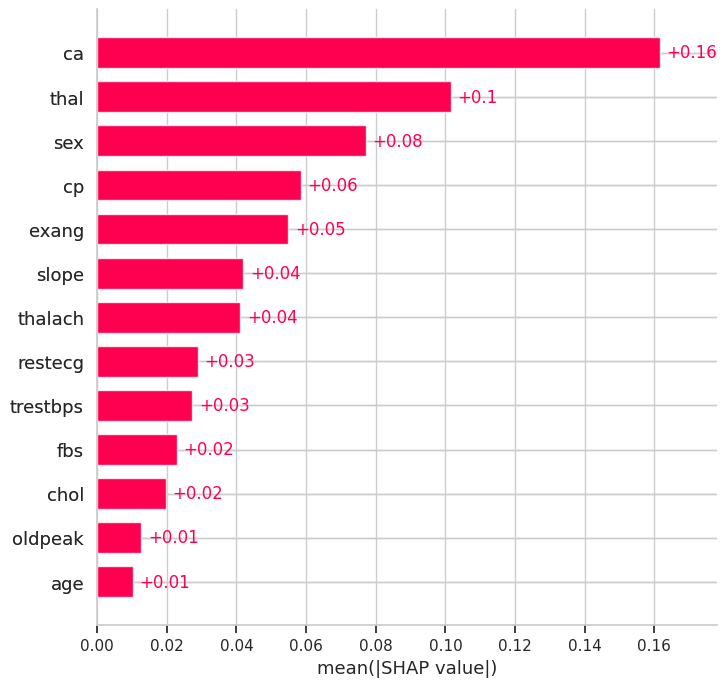

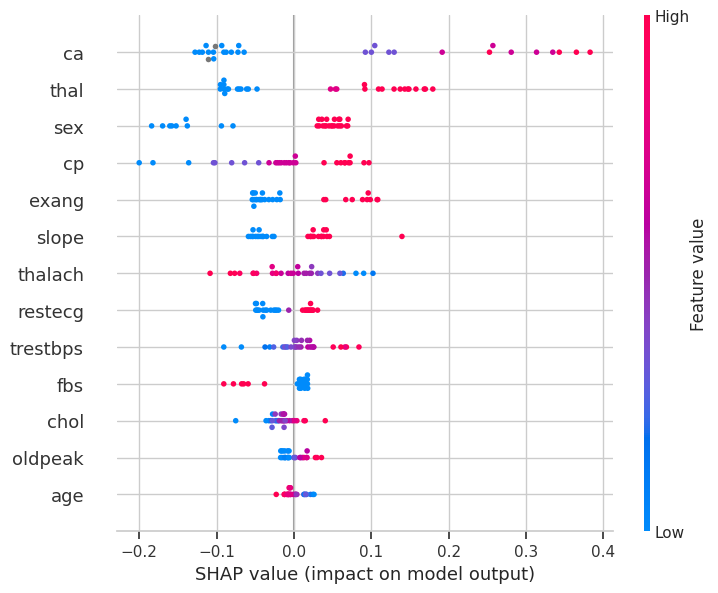

In [16]:
# Global explanation: which features influence predictions most?
shap.plots.bar(shap_values, max_display=13)

# Detailed feature impact plot
shap.plots.beeswarm(shap_values, max_display=13)

Predicted class: 0
Interpretation: No disease predicted
Model-estimated probability for class 1: 0.246


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
219,59,1,4,138,271,0,2,182,0,0.0,1,0.0,3.0


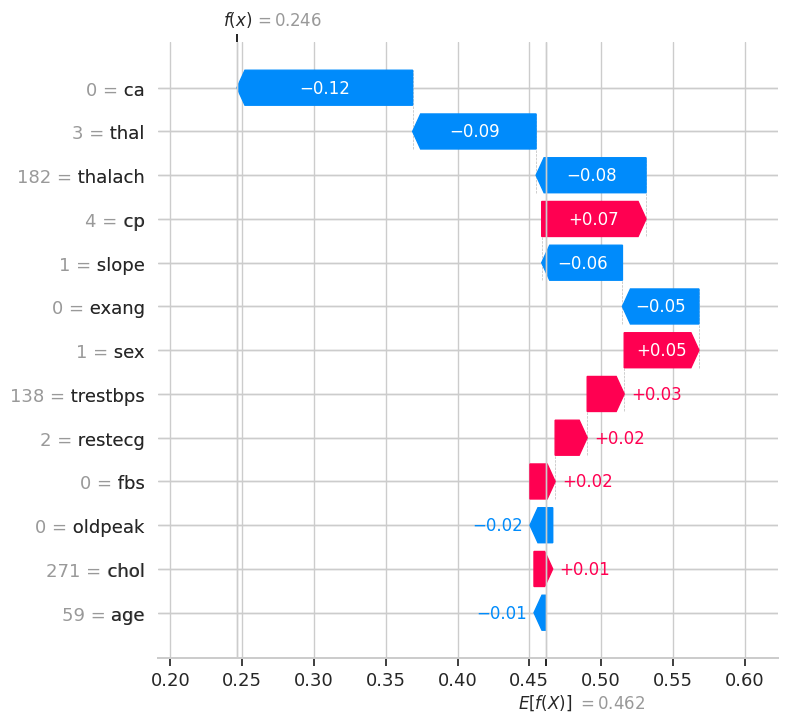

In [17]:
# Explain the first record in the selected test sample
sample = explain_data.iloc[[0]]

predicted_class = int(best_model.predict(sample)[0])
predicted_probability = float(best_model.predict_proba(sample)[0, 1])

print("Predicted class:", predicted_class)
print(
    "Interpretation:",
    "Disease present" if predicted_class == 1 else "No disease predicted"
)
print(f"Model-estimated probability for class 1: {predicted_probability:.3f}")

display(sample)

# Local SHAP explanation for this sample
shap.plots.waterfall(shap_values[0], max_display=13)

In [18]:
# Save the fitted pipeline, including its preprocessing steps
joblib.dump(best_model, "heart_disease_model.joblib")

# Save model comparison and final test metrics
cv_results_df.to_csv("model_comparison.csv", index=False)

test_metrics_df = pd.DataFrame(
    list(test_metrics.items()),
    columns=["Metric", "Test Score"]
)
test_metrics_df.to_csv("test_metrics.csv", index=False)

# Save the dataset used in the experiment
df.to_csv("heart_disease_cleaned.csv", index=False)

print("Files saved:")
print("- heart_disease_model.joblib")
print("- model_comparison.csv")
print("- test_metrics.csv")
print("- heart_disease_cleaned.csv")

Files saved:
- heart_disease_model.joblib
- model_comparison.csv
- test_metrics.csv
- heart_disease_cleaned.csv


In [19]:
from google.colab import files

files.download("heart_disease_model.joblib")
files.download("model_comparison.csv")
files.download("test_metrics.csv")
files.download("heart_disease_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>